RNN - LTSM Model
-

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.autograd import Variable
from sklearn.preprocessing import MinMaxScaler
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [74]:
dataset_ts = pd.read_csv("FRED-NROUST.csv")
dataset_ts

,Date,Value
0,01-01-1949,5.255053
1,01-04-1949,5.261516
2,01-07-1949,5.268013
3,01-10-1949,5.274564
4,01-01-1950,5.281182
...,...,...
291,01-10-2021,4.450651
292,01-01-2022,4.445137
293,01-04-2022,4.440214
294,01-07-2022,4.435784


In [75]:
test_size = 19
seq_length =10 # less than test size always

In [76]:
dataset_train = dataset_ts.iloc[:-test_size,:10].values
dataset_test = dataset_ts.iloc[-test_size:,:10].values
training_set = dataset_train[:,1:2]
testing_set = dataset_test[:,1:2]
sc = MinMaxScaler()
training_set_scaled = sc.fit_transform(training_set)
testing_set_scaled = sc.transform(testing_set)
training_set_scaled.shape, testing_set_scaled.shape

((277, 1), (19, 1))

In [77]:
def sliding_windows(data,seq_length):
    x= []
    y =[]

    for i in range(len(data)-seq_length-1): # 19 - 10 -1 => 8 Obs IN TEST
        _x = data[i:(i+seq_length)]
        _y = data[i+seq_length]
        x.append(_x)
        y.append(_y)

    return np.array(x),np.array(y)

In [78]:
X_train, y_train= sliding_windows(training_set_scaled,seq_length)
X_test,y_test = sliding_windows(testing_set_scaled,seq_length)
X_train.shape,y_train.shape,X_test.shape,y_test.shape

((266, 10, 1), (266, 1), (8, 10, 1), (8, 1))

In [79]:
trainX = Variable(torch.Tensor(np.array(X_train)))
trainY = Variable(torch.Tensor(np.array(y_train)))

testX = Variable(torch.Tensor(np.array(X_test)))
testY = Variable(torch.Tensor(np.array(y_test)))
trainX.shape, trainY.shape,testX.shape, testY.shape

(torch.Size([266, 10, 1]),
 torch.Size([266, 1]),
 torch.Size([8, 10, 1]),
 torch.Size([8, 1]))

In [80]:
class LSTM(nn.Module):
    def __init__(self, num_classes, input_size,hidden_size,num_layers):
        super(LSTM,self).__init__()

        self.num_classes = num_classes
        self.num_layers = num_layers
        self.input_size = input_size
        self.hidden_size = hidden_size
        # self.seq_length = seq_length

        self.lstm = nn.LSTM(input_size =input_size,hidden_size=hidden_size,num_layers=num_layers,batch_first=True)
        self.fc = nn.Linear(hidden_size,num_classes)

    def forward(self,x):
        h_0 = Variable(torch.zeros(self.num_layers,x.size(0),self.hidden_size))
        c_0 = Variable(torch.zeros(self.num_layers,x.size(0),self.hidden_size))
        ula, (h_out,_) = self.lstm(x,(h_0,c_0)) # propogate input through LSTM
        h_out = h_out.view(-1,self.hidden_size)
        out = self.fc(h_out)

        return out

In [81]:
num_epochs = 2000
learning_rate = 0.01
input_size, hidden_size, num_layers,num_classes=1,2,1,1

lstm =LSTM(num_classes,input_size,hidden_size,num_layers)
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(lstm.parameters(),lr=learning_rate)
for epoch in range(num_epochs):
    outputs = lstm(trainX)
    optimizer.zero_grad()
    loss = criterion(outputs,trainY)
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print("Epoch: %d, loss: %1.5f" % (epoch,loss.item()))

Epoch: 0, loss: 0.96152
Epoch: 100, loss: 0.04536
Epoch: 200, loss: 0.02751
Epoch: 300, loss: 0.00202
Epoch: 400, loss: 0.00143
Epoch: 500, loss: 0.00116
Epoch: 600, loss: 0.00097
Epoch: 700, loss: 0.00083
Epoch: 800, loss: 0.00073
Epoch: 900, loss: 0.00065
Epoch: 1000, loss: 0.00058
Epoch: 1100, loss: 0.00053
Epoch: 1200, loss: 0.00048
Epoch: 1300, loss: 0.00043
Epoch: 1400, loss: 0.00039
Epoch: 1500, loss: 0.00035
Epoch: 1600, loss: 0.00031
Epoch: 1700, loss: 0.00027
Epoch: 1800, loss: 0.00023
Epoch: 1900, loss: 0.00020


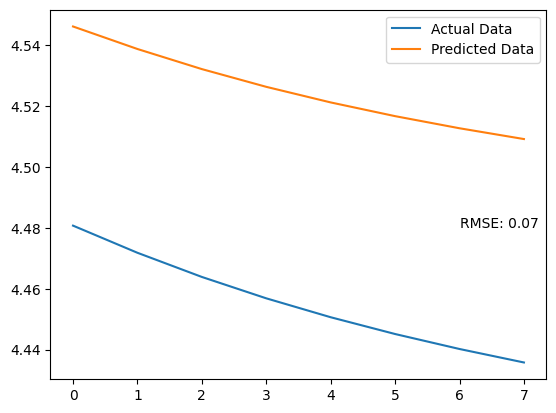

In [82]:
from sklearn.metrics import root_mean_squared_error

lstm.eval()
test_predict = lstm(testX)
data_predict = test_predict.data.numpy()
dataY_plot = testY.data.numpy()
data_predict = sc.inverse_transform(data_predict)
dataY_plot = sc.inverse_transform(dataY_plot)
plt.plot(dataY_plot, label = 'Actual Data')
plt.plot(data_predict, label='Predicted Data')
rmse = root_mean_squared_error(dataY_plot,data_predict)
plt.legend()
plt.text(6,4.48,'RMSE: %.2f' % rmse)
plt.show()

In [83]:
dataY_plot.shape,data_predict.shape

((8, 1), (8, 1))